In [1]:
!wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

--2026-10-12 10:46:08--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.005s  

2026-10-12 10:46:09 (49.4 MB/s) - ‘course_lead_scoring_2026.csv’ saved [278746/278746]



In [2]:
import pandas as pd
import numpy as np
import seaborn as sns

In [19]:
data = pd.read_csv("course_lead_scoring_2026.csv")

In [4]:
data.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [20]:
data.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [11]:
data.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [12]:
data.nunique()

lead_source                    5
industry                       6
employment_status              4
location                       5
annual_income               4313
number_of_courses_viewed       7
interaction_count             14
lead_score                    99
converted                      2
dtype: int64

In [34]:
numerical = ['annual_income',
             'lead_score',
             'number_of_courses_viewed',
             'interaction_count']
categorical = ['lead_source',
               'industry',
               'employment_status',
               'location'
              ]

In [22]:
data[numerical] = data[numerical].fillna(0.0)

In [23]:
data[categorical] = data[categorical].fillna('NA')

In [24]:
data.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [25]:
data.industry.mode()

0    technology
Name: industry, dtype: str

In [28]:
correlation_matrix = data[numerical].corr()

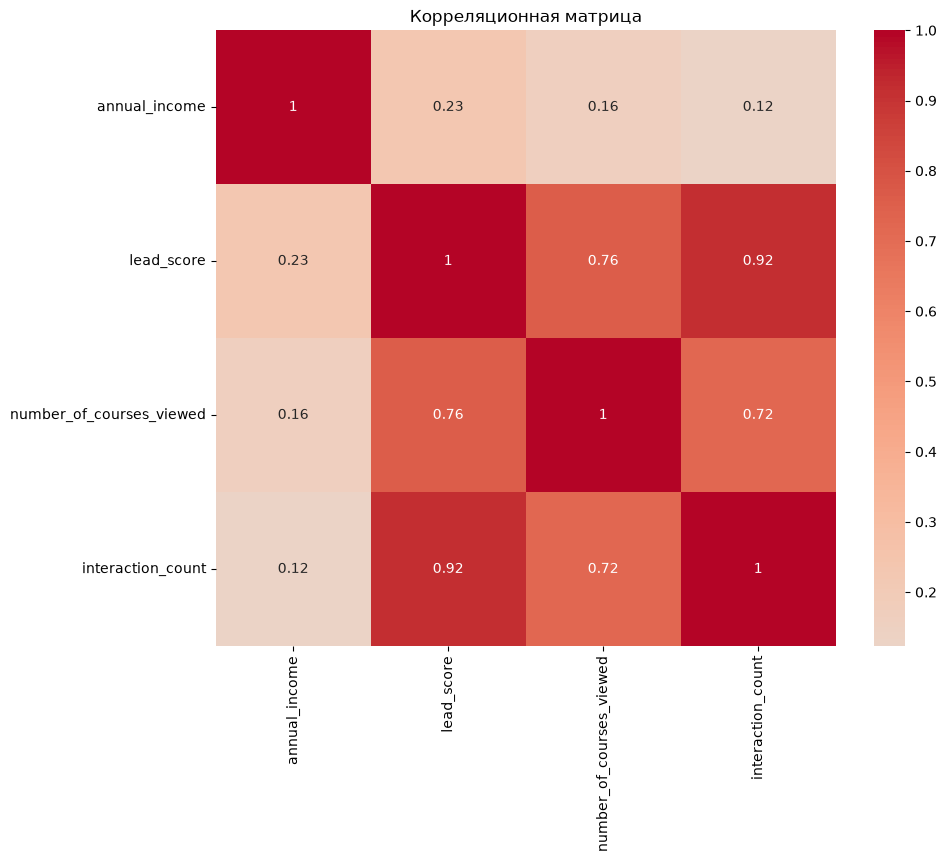

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Корреляционная матрица')
plt.show()

In [31]:
from sklearn.model_selection import train_test_split

In [33]:
df_full_train, df_test = train_test_split(data, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

In [56]:
X_train = df_train.drop(columns=['converted'])
X_val = df_val.drop(columns=['converted'])
X_test = df_test.drop(columns=['converted'])

In [36]:
y_train = df_train.converted
y_val = df_val.converted
y_test = df_test.converted

In [39]:
from sklearn.metrics import mutual_info_score

In [44]:
def mutual_info_converted_score(series):
    return np.round(mutual_info_score(series, y_train), 2)

In [45]:
mi = X_train[categorical].apply(mutual_info_converted_score)
mi.sort_values(ascending=False)

lead_source          0.03
employment_status    0.02
industry             0.00
location             0.00
dtype: float64

In [46]:
from sklearn.feature_extraction import DictVectorizer

In [47]:
dv = DictVectorizer(sparse=False)

train_dict = X_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = X_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

In [49]:
from sklearn.linear_model import LogisticRegression

In [50]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [51]:
converted_pred = model.predict(X_val)

In [55]:
(converted_pred == y_val).mean()

np.float64(0.645)

In [58]:
accuracy_list = []

elimination_features = ['lead_source', 'number_of_courses_viewed', 'interaction_count']
for p in elimination_features:
    X_train = df_train.drop(columns=['converted', p])
    X_val = df_val.drop(columns=['converted', p])
    X_test = df_test.drop(columns=['converted', p])

    y_train = df_train.converted
    y_val = df_val.converted
    y_test = df_test.converted

    dv = DictVectorizer(sparse=False)

    train_dict = X_train.to_dict(orient='records')
    X_train = dv.fit_transform(train_dict)
    
    val_dict = X_val.to_dict(orient='records')
    X_val = dv.transform(val_dict)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)

    converted_pred = model.predict(X_val)
    accuracy_list.append(0.645 - (converted_pred == y_val).mean())

dict(zip(elimination_features, accuracy_list))

{'lead_source': np.float64(0.0030000000000000027),
 'number_of_courses_viewed': np.float64(0.0020000000000000018),
 'interaction_count': np.float64(0.04400000000000004)}

In [59]:
C = [0.000001, 0.00001, 0.0001, 0.001]
accuracy_list = []

for c in C:
    X_train = df_train.drop(columns=['converted'])
    X_val = df_val.drop(columns=['converted'])
    X_test = df_test.drop(columns=['converted'])

    y_train = df_train.converted
    y_val = df_val.converted
    y_test = df_test.converted

    dv = DictVectorizer(sparse=False)

    train_dict = X_train.to_dict(orient='records')
    X_train = dv.fit_transform(train_dict)
    
    val_dict = X_val.to_dict(orient='records')
    X_val = dv.transform(val_dict)

    model = LogisticRegression(solver='liblinear', C=c, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)

    converted_pred = model.predict(X_val)
    accuracy_list.append(np.round((converted_pred == y_val).mean(), 3))

dict(zip(C, accuracy_list))

{1e-06: np.float64(0.598),
 1e-05: np.float64(0.598),
 0.0001: np.float64(0.613),
 0.001: np.float64(0.645)}